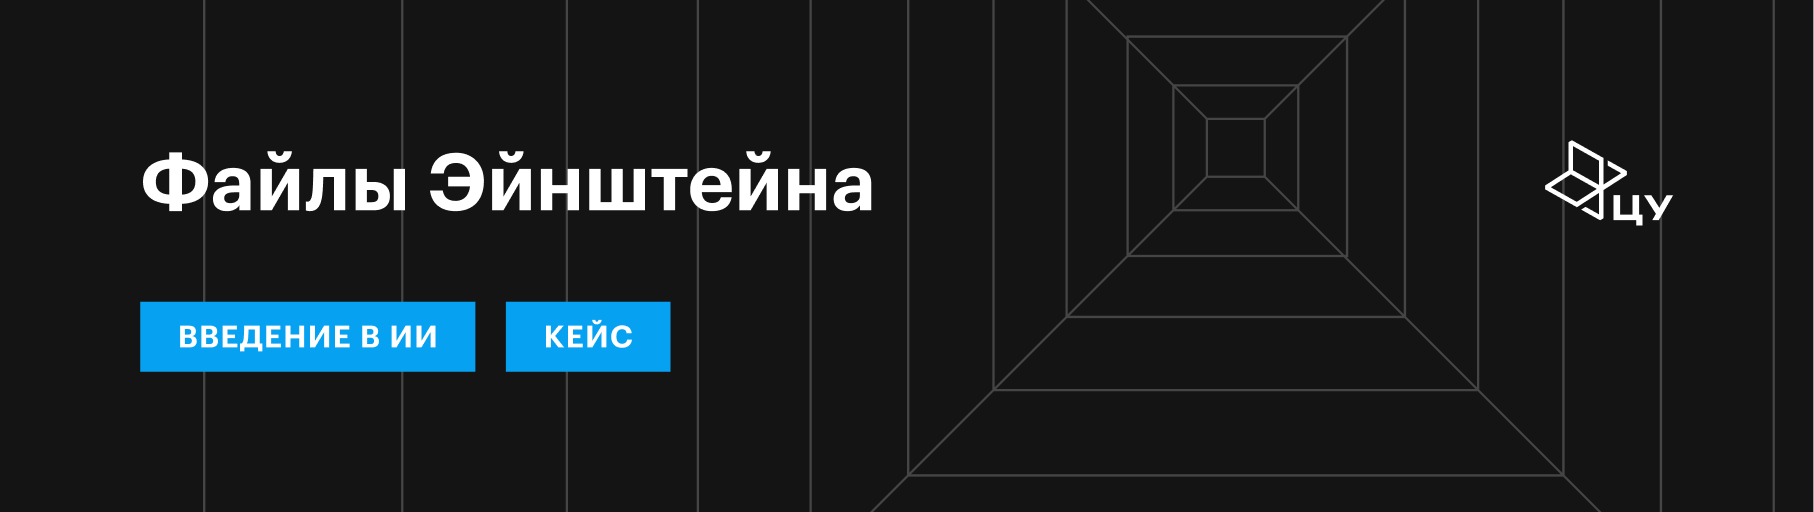

# Легенда

Ты работаешь в компании Х, которая занимается исследованием и сортировкой документов.
Недавно к тебе в руки попал ранее скрытый от глаз общественности материал *«Файлы Эйнштейна»*, содержащий тексты писем, написанных от руки великим учёным.

Один стажёр уже отсканировал файлы и начал вручную их расшифровывать. Однако старый офисный сканер оставил ошибки и артефакты на текстах, а вкупе с неразборчивым почерком Альберта Эйнштейна эта задача оказалась невыполнимой.

Поэтому твой начальник обратился к тебе с просьбой: «Сделайте так, чтобы компьютер сам всё прочитал. И чтобы потом можно было найти слово «бомба» или «антивселенная»: мало ли что там у этого Эйнштейна было на уме».

**Задача:** создать нейросетевую модель OCR, которая сможет распознавать рукописный текст Эйнштейна с максимальной точностью.

# Требования к решению

Поскольку это учебный проект, вводятся следующие технические ограничения.

* **Ограничение по размеру модели:** решение должно корректно работать в Google Colab. Использовать несколько Google-аккаунтов для увеличения квоты на Т4 для экспериментов с архитектурой не запрещено.

* **Воспроизводимость:** весь код должен выполняться последовательно с первого раза. Обязательно фиксируй random_seed, а также сохраняй веса моделей и логируй эксперимент.

**Необходимые этапы решения**

1. *Обработка данных*. Внимательно изучи данные в датасете `einstein_files`. Предложи способ выделения символов из текста. Подумай, можно ли применять модель к сырым данным или нужно провести некоторые манипуляции.


2. *Выбор модели*. Напиши свою модель классификации рукописных букв английского алфавита или выбери предобученную.


3. *Решение задачи распознавания символов*. Обучение выбранной модели на датасете. Опиши, как осуществлялись подбор гиперпараметров, выбор метрики и валидация.

4. *Применение модели*. Финальный этап решения: объедини две основные составляющие в одну (выделение символов из изображения, их обработка моделью распознавания символов, составление полного текста). Результаты OCR будут проверяться по метрикам accuracy.

# Система оценивания

Решение оценивается по трём параметрам.
* **Работа с данными [4 балла].** Оценка ставится в соответствии с тем, насколько подробно была произведена работа с данными. Визуализации, предобработка и очистка/обогащение датасета будут плюсом.

* **Решение задачи [4 балла].** Оценка ставится не за итоговые метрики (для простых моделей их значение может быть небольшим), а за то, насколько качественно были проделаны эксперименты в рамках выбранной модели. То есть если в решении используется примитивная модель, получающая низкие метрики, но она обучена с разными гиперпараметрами и приёмами так, что из её качества выжимается максимум, то это решение будет оценено в полный балл.

* **Оформление [2 балла].** Хочется, чтобы написанный код читался как хорошая книга. Для этого мы добавляем баллы за оформление, если в коде появляются визуализации, комментарии к коду и сопроводительный текст.

# Данные

Ниже написан код для скачивания датасета `einstien_files`, который содержит 46 изображений отсканированных документов с рукописным текстом на английском языке.

In [ ]:
!gdown 1gMlho_Jrzuy2Lt-8rKZa8gr7jo_RiMUQ
!unzip -q /content/einstein_files.zip
!rm /content/einstein_files.zip

Downloading...
From: https://drive.google.com/uc?id=1gMlho_Jrzuy2Lt-8rKZa8gr7jo_RiMUQ
To: /content/einstein_files.zip
100% 4.81M/4.81M [00:00<00:00, 13.9MB/s]


# Твой код

Ниже представлен вариант решения кейса.

In [ ]:
# Импорт необходимых библиотек
import matplotlib.pyplot as plt
import cv2
import numpy as np
import torch
from torch.utils.data import Dataset
from torchvision import datasets, transforms

## Обучение модели OCR

В этом разделе ты обучаешь свою модель распознавания символов.

**Подсказка:** для обучения модели стоит выбрать датасет, содержащий рукописные буквы на английском языке.

In [ ]:
# Твой код для модели и её обучения здесь

# Обработка данных

В этом разделе ты обрабатываешь полученные файлы Эйнштейна в удобный для твоей модели формат.

**Подсказка:** внимательно изучи данные в датасете. Подумай, как можно выделить каждый символ в тексте, для того чтобы подать его в нейросеть.

In [ ]:
class EinsteinFilesDataset(Dataset):
    # Твой код для обработки данных здесь
    pass

In [ ]:
einstein_files = ... # Твой код здесь

# Итог

В этом разделе мы подведём итоги обработки данных и обучения модели OCR. Для этого мы используем две метрики — **Character Error Rate** (CER) и **Word Error Rate** (WER).

1. CER вычисляется как расстояние Левенштейна между исходным текстом и распознанным, делённое на количество символов.

2. WER вычисляется как процент совпадающих слов.

In [ ]:
!pip install Levenshtein

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 153.3/153.3 kB 6.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 43.2 MB/s eta 0:00:00


In [ ]:
from Levenshtein import distance

def character_error_rate(pred_text, real_text):
    """Расстояние Левенштейна"""
    return distance(pred_text, real_text) / len(real_text)

In [ ]:
def word_error_rate(pred_text, real_text):
    """Процент слов, распознанных с ошибкой"""
    pred_words = pred_text.split()
    true_words = real_text.split()

    if len(true_words) == 0:
        return 0 if len(pred_words) == 0 else 1.0

    errors = sum(1 for p, t in zip(pred_words, true_words) if p != t)
    errors += abs(len(pred_words) - len(true_words))

    return errors / len(true_words)

Напиши функцию для обработки файлов Эйнштейна. Она должна принимать на вход датасет `epstein_files` (чтение данных и их обработку ты выбираешь и реализовываешь самостоятельно) и твою модель OCR `model`. На выходе — распознанный текст.

In [ ]:
def process(einstein_files, model):
    # Твой код здесь
    pass

In [ ]:
pred_text = ... # Твой код здесь

Прочитай текстовый файл с реальным текстом файлов Эйнштейна и оцени качество модели с помощью метрик выше.

**ВНИМАНИЕ.** Данный файл в целях академической честности может быть прочтён и использован только в части кода снизу.

In [ ]:
!gdown 1hF7HHyIROhPoVOzQnBiqjfYtJ6v4raJC

In [ ]:
with open('top_secret.txt', 'r', encoding='utf-8') as file:
    real_text = file.read().lower()

In [ ]:
wer = word_error_rate(pred_text, real_text)
cer = character_error_rate(pred_text, real_text)
print(f"WER = {wer}")
print(f"CER = {cer}")

**Выводы:** опиши, как ты пришёл(-ла) к решению, какие модели использовались, как проходил подбор гиперпараметров, как работал(а) с данными, с какими проблемами столкнулся(ась) и прочее.